# Isospectral drums: dataset playground

Two different polygons can have the same Dirichlet spectrum. Here we try
**independent vertex jitter** and a **shared scaling control** before training any models.
Jitter is not guaranteed to preserve isospectrality; shared scaling does.
Scaling changes size, not the underlying shape.

Construction: [Chapman, *Drums That Sound the Same*](https://www.math.ucdavis.edu/~saito/courses/ACHA.READ.F03/drum-chapman.pdf).

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
os.environ["JAX_PLATFORMS"] = "cpu"
from drums.data.spectrum import get_drum_spectrum
%matplotlib inline

## 1. Original pair

Vertices follow the boundary in order. Both drums have area 3.5.

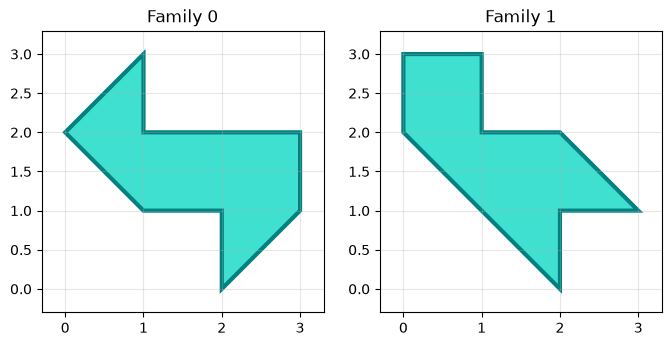

In [2]:
drums = np.array([
    [[0, 2], [1, 1], [2, 1], [2, 0], [3, 1], [3, 2], [1, 2], [1, 3]],
    [[0, 3], [0, 2], [2, 0], [2, 1], [3, 1], [2, 2], [1, 2], [1, 3]],
], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for family, ax in enumerate(axes):
    ax.fill(*drums[family].T, facecolor="turquoise", edgecolor="teal", linewidth=3)
    ax.set(title=f"Family {family}", aspect="equal", xlim=(-0.3, 3.3), ylim=(-0.3, 3.3))
    ax.grid(alpha=0.3)
plt.show()

In [3]:
n_eig = 30
n_elements = 4000  # target mesh resolution, relative to polygon area

def area(vertices):
    x, y = vertices.T
    return abs(np.sum(x * np.roll(y, -1) - y * np.roll(x, -1))) / 2

def spectrum(vertices, resolution=n_elements):
    values, _, _, _ = get_drum_spectrum(vertices, N_eig=n_eig, a=area(vertices) / resolution)
    return np.sort(values)

def relative_gap(a, b):
    return np.abs(a - b) / ((a + b) / 2)

## 2. Numerical error on the original pair

The exact spectra agree, but separate FEM meshes introduce small differences.
Increase the resolution to check convergence. All gaps below are relative percentages.

In [4]:
original_spectra = {}
rows = []
for resolution in [n_elements, 4 * n_elements]:
    values = np.array([spectrum(drum, resolution) for drum in drums])
    original_spectra[resolution] = values
    gap = 100 * relative_gap(values[0], values[1])
    rows.append({"target elements": resolution,
                 "mean gap (%)": gap.mean(), "max gap (%)": gap.max()})

fine_spectra = original_spectra[4 * n_elements]
pd.DataFrame(rows)

,target elements,mean gap (%),max gap (%)
0,4000,0.017074,0.057599
1,16000,0.002606,0.011381


## 3. Independent coordinate jitter

Each vertex receives independent uniform noise on both axes. These are **two nearby
shape families**, not proven isospectral partners. Even small spectral differences
may reveal the family. The simple playground restricts jitter to at most 0.1 to keep
these particular polygons safely separated from self-intersections.

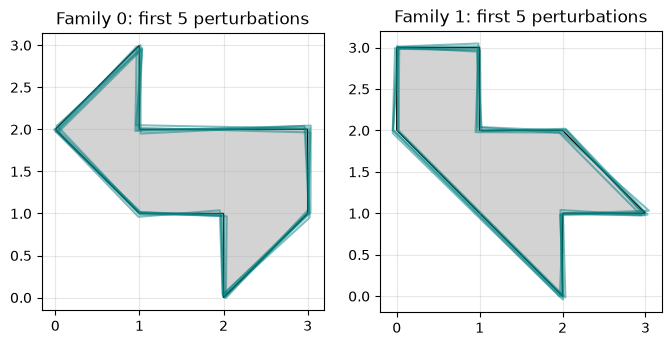

In [5]:
seed = 17
n_pairs = 20
epsilon = 0.05  # each x and y coordinate changes by at most this amount
assert 0 <= epsilon <= 0.1
rng = np.random.default_rng(seed)
jittered = drums[None] + rng.uniform(-epsilon, epsilon, size=(n_pairs, *drums.shape))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for family, ax in enumerate(axes):
    ax.fill(*drums[family].T, facecolor="lightgrey", edgecolor="black", label="Original")
    for pair in jittered[:5]:
        outline = np.vstack([pair[family], pair[family, 0]])
        ax.plot(*outline.T, color="teal", alpha=0.5)
    ax.set(title=f"Family {family}: first 5 perturbations", aspect="equal")
    ax.grid(alpha=0.3)
plt.show()

In [6]:
# Keep each perturbed polygon's own spectrum; do not copy it to the other family.
jitter_spectra = np.array([[spectrum(drum) for drum in pair] for pair in jittered])
jitter_gaps = 100 * relative_gap(jitter_spectra[:, 0], jitter_spectra[:, 1])
gap_table = pd.DataFrame({"mean gap (%)": jitter_gaps.mean(axis=1),
                          "max gap (%)": jitter_gaps.max(axis=1)})
gap_table.describe().loc[["min", "mean", "50%", "max"]].rename(index={"50%": "median"})

,mean gap (%),max gap (%)
min,1.361171,4.543934
mean,3.465202,8.440485
median,3.133234,8.254041
max,7.515902,15.125602


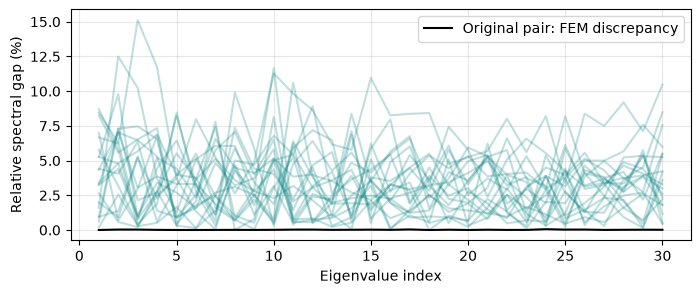

In [7]:
plt.figure(figsize=(8, 3))
for gap in jitter_gaps:
    plt.plot(np.arange(1, n_eig + 1), gap, color="teal", alpha=0.25)
baseline = original_spectra[n_elements]
plt.plot(np.arange(1, n_eig + 1), 100 * relative_gap(*baseline),
         color="black", label="Original pair: FEM discrepancy")
plt.xlabel("Eigenvalue index")
plt.ylabel("Relative spectral gap (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Shared scaling: a clean ambiguity control

For each scale, both partners have the same spectrum because
$\lambda_k(s\Omega)=\lambda_k(\Omega)/s^2$.
We use one fine-mesh numerical reference and apply this exact scaling law.
The reference itself is still an approximation. Both family labels receive the
same conditioning vector here; this would not be justified for independent jitter.

In [8]:
rng = np.random.default_rng(seed + 1)
scales = rng.uniform(0.95, 1.05, n_pairs)
centres = drums.mean(axis=1, keepdims=True)
scaled = np.array([centres + s * (drums - centres) for s in scales])
reference = fine_spectra[0]
scaled_spectra = np.array([[reference / s**2, reference / s**2] for s in scales])

pd.DataFrame({"scale": scales, "lambda_1, family 0": scaled_spectra[:, 0, 0],
              "lambda_1, family 1": scaled_spectra[:, 1, 0]}).head()

,scale,"lambda_1, family 0","lambda_1, family 1"
0,0.989931,10.371254,10.371254
1,1.021741,9.735510,9.735510
2,0.978082,10.624045,10.624045
3,0.958272,11.067836,11.067836
4,1.046977,9.271849,9.271849


## 5. Prepare a small dataset

Choose `"jitter"` or `"scaling"`. Both families of each pair stay in the same split.
For jitter, a pair is simply a sampling group, not an isospectral match.
`family` and `pair_id` are evaluation labels, not model inputs.

For the scaling control, score valid solutions from either family and measure mode coverage. Do not average generated shapes across the two modes.

In [9]:
mode = "scaling"  # or "jitter"
perimeters, spectra = {"jitter": (jittered, jitter_spectra),
                       "scaling": (scaled, scaled_spectra)}[mode]
pair_id = np.repeat(np.arange(n_pairs), 2)
family = np.tile([0, 1], n_pairs)
rng = np.random.default_rng(seed + 2)
test_pairs = rng.permutation(n_pairs)[int(0.8 * n_pairs):]
split = np.where(np.isin(pair_id, test_pairs), "test", "train")

dataset = dict(perimeters=perimeters.reshape(-1, 8, 2), spectra=spectra.reshape(-1, n_eig),
               pair_id=pair_id, family=family, split=split, mode=mode, seed=seed,
               n_elements=4 * n_elements if mode == "scaling" else n_elements)
if mode == "scaling":
    dataset["scales"] = scales
else:
    dataset["epsilon"] = epsilon
print("Perimeters:", dataset["perimeters"].shape, "Spectra:", dataset["spectra"].shape)
pd.crosstab(split, family, rownames=["split"], colnames=["family"])

Perimeters: (40, 8, 2) Spectra: (40, 30)


family,0,1
split,,
test,4,4
train,16,16


Optional: save one `.npz` file. Saving is disabled by default; an existing file is not overwritten.

In [10]:
save = False
path = root / f"isospectral_{mode}_pilot.npz"
if save:
    if path.exists():
        raise FileExistsError(path)
    np.savez_compressed(path, **dataset)
    print(path)